# Power analysis GWAS synthetic data

In [199]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

In [200]:
humans = pd.read_csv('./data/phenotype/all.panel',delim_whitespace=True)

In [201]:
humans

,sample,sample.1,pop,super_pop,gender
0,HG00096,HG00096,GBR,EUR,male
1,HG00097,HG00097,GBR,EUR,female
2,HG00099,HG00099,GBR,EUR,female
3,HG00100,HG00100,GBR,EUR,female
4,HG00101,HG00101,GBR,EUR,male
...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female
2500,NA21141,NA21141,GIH,SAS,female
2501,NA21142,NA21142,GIH,SAS,female
2502,NA21143,NA21143,GIH,SAS,female


In [202]:
os.listdir('./data/genotype')

['0_0_115_0_maf_0.01_0.01.pkl',
 '21_9_120_21_maf_0.024_0.025.pkl',
 '38_9_120_38_maf_0.048_0.05.pkl',
 '138_9_80_138_maf_0.49_0.49.pkl',
 '60_2_120_60_maf_0.1_0.1.pkl',
 '97_4_80_97_maf_0.25_0.25.pkl']

In [203]:
wanted_maf = '0.01_0.01'

In [204]:
snps = [f for f in os.listdir('./data/genotype') if f.split("_maf_")[1].split('.pkl')[0] == wanted_maf]

In [205]:
for snp in snps:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    path_snp = f"./data/genotype/{snp}"
    print(path_snp)

./data/genotype/0_0_115_0_maf_0.01_0.01.pkl


In [206]:
geno = pd.read_pickle(path_snp)

In [207]:
geno

,21:47359014:A:G_G,21:46996874:A:G_A,21:45481023:A:T_T,21:25855869:A:T_A,21:40585488:C:G_C,21:35885386:A:C_C,21:18744903:A:G_A,21:45271907:A:G_A,21:36633157:A:G_G,21:18344855:A:C_C,...,21:14658502:A:G_G,21:22674486:C:T_T,21:16122266:A:T_T,21:30087521:C:T_T,21:34175274:G:T_G,21:40414537:G:T_G,21:24991615:C:G_G,21:47576005:C:T_C,21:34185714:C:T_T,21:30091736:C:T_C
0,1,1,1,1,1,1,0,1,1,1,...,1,1,1,1,1,1,1,1,1,1
1,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
2,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
3,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
4,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2499,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
2500,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
2501,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
2502,1,1,1,1,1,1,0,1,1,1,...,1,1,1,1,1,1,1,1,1,0


In [208]:
i = 0

In [209]:
geno[geno.columns[i]].value_counts()

1    2454
0      50
Name: 21:47359014:A:G_G, dtype: int64

In [210]:
geno[geno.columns[i]].value_counts()
num_maj = geno[geno.columns[i]].value_counts()[1]
num_het = geno[geno.columns[i]].value_counts()[0]
try:
    num_min = geno[geno.columns[i]].value_counts()[-1]
except Exception as e:
    num_min = 0
total_humans = num_maj + num_het + num_min

In [211]:
num_maj/total_humans

0.9800319488817891

In [212]:
maf = (num_min*2 + num_het)/(total_humans*2)
maf

0.009984025559105431

In [213]:
1 - maf*2

0.9800319488817891

In [214]:
num_maj/total_humans

0.9800319488817891

In [215]:
mean_min = 115
mean_het = 150
mean_maj = 160

In [216]:
sigma_min = 1
sigma_het = 1
sigma_maj = 1

In [217]:
humans

,sample,sample.1,pop,super_pop,gender
0,HG00096,HG00096,GBR,EUR,male
1,HG00097,HG00097,GBR,EUR,female
2,HG00099,HG00099,GBR,EUR,female
3,HG00100,HG00100,GBR,EUR,female
4,HG00101,HG00101,GBR,EUR,male
...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female
2500,NA21141,NA21141,GIH,SAS,female
2501,NA21142,NA21142,GIH,SAS,female
2502,NA21143,NA21143,GIH,SAS,female


In [218]:
geno[geno.columns[i]]

0       1
1       1
2       1
3       1
4       1
       ..
2499    1
2500    1
2501    1
2502    1
2503    1
Name: 21:47359014:A:G_G, Length: 2504, dtype: int64

In [219]:
pheno = []
for var in list(geno[geno.columns[i]]):
    if var == 1:
        pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
    elif var == 0:
        pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
    else:
        pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])

In [220]:
df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[i]]), "pheno": pheno})

In [221]:
df_pheno

,geno,pheno
0,1,159.372702
1,1,160.035350
2,1,161.557906
3,1,160.719450
4,1,158.551527
...,...,...
2499,1,159.677934
2500,1,159.479670
2501,1,160.263299
2502,1,160.081229


<AxesSubplot:xlabel='geno', ylabel='pheno'>

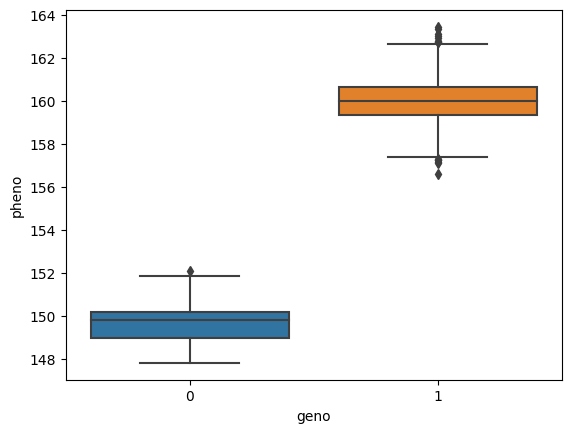

In [222]:
sns.boxplot(data=df_pheno, x="geno", y="pheno")

In [223]:
X = df_pheno[['geno']]
y = df_pheno[['pheno']]

In [224]:
reg = LinearRegression().fit(X, y)

In [225]:
reg.score(X, y)

0.6807716945557754

In [226]:
reg.coef_[0][0]

10.253836061226115

In [227]:
reg.intercept_[0]

149.7418495247613

In [228]:
def find_lin_reg(X):
    y = reg.coef_[0][0]*X + reg.intercept_[0]
    return y

In [229]:
find_lin_reg(1)

159.99568558598742

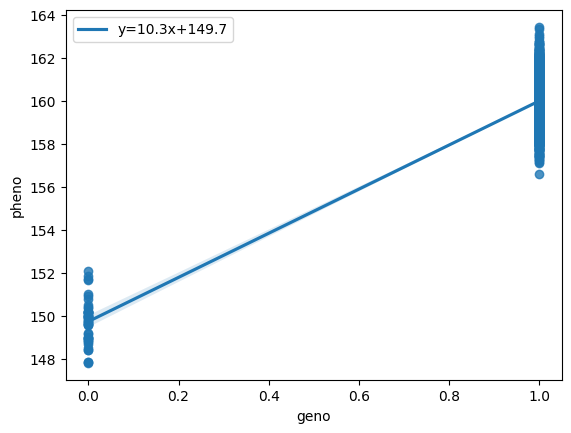

In [230]:
# use line_kws to set line label for legend
ax = sns.regplot(x="geno", y="pheno", data=df_pheno, 
 line_kws={'label':"y={0:.1f}x+{1:.1f}".format(reg.coef_[0][0],reg.intercept_[0])})

# plot legend
ax.legend()

plt.show()